### Top Rows

In [354]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display, HTML

def display_scroll(df, height="400px"):
    display(HTML(f"""
    <div style="max-height:{height}; overflow:auto; border:1px solid #ccc; padding:5px;">
        {df.to_html()}
    </div>
    """))
file_path = "results-filtered.xlsx"
# df = pd.read_excel(file_path, sheet_name="kPEX")
df = pd.read_excel(file_path, sheet_name="UMKP+AltRB")
# versions="v0 v1 v2 v3 v4".split()
versions="v0 v1 v2 v3".split()
branchings="S R P".split()

for v in versions: 
    df[f"{v}-prep"] = (df[f"{v}-S-bnb"] == "prep")
    cols = [f"{v}-{b}-ctcp" for b in branchings]
    df[f"{v}-ctcp"] = (
        df[cols]
        .apply(pd.to_numeric, errors="coerce")  # non-numeric → NaN
        .mean(axis=1)                           # skips NaN automatically
    )
    cols = [f"{v}-{b}-heur" for b in branchings]
    df[f"{v}-heur"] = (
        df[cols]
        .apply(pd.to_numeric, errors="coerce")  # non-numeric → NaN
        .mean(axis=1)                           # skips NaN automatically
    )    

    
def clean_dataframe(df):
    df = df.dropna(axis=1, how="all")
    df = df.copy()

    def convert_col(col):
        # replace exact matches first
        col = col.replace({"x": 1800, "prep": 0})
        
        # try numeric conversion WITHOUT destroying original values
        numeric = pd.to_numeric(col, errors="coerce")
        
        # keep original where conversion failed
        return numeric.where(~numeric.isna(), col)

    return df.apply(convert_col)

df = clean_dataframe(df)

for v in versions: 
    df[f"{v}-init"] = df[f"{v}-heur"]+df[f"{v}-ctcp"]
    df[f"{v}-prep"] = df[f"{v}-prep"].replace(False, "")
    
df.head()
pd.set_option('display.float_format', '{:.1f}'.format)
pd.set_option('display.max_rows', 50)
pd.set_option('display.max_columns', None)

/var/folders/fg/pzhds6gn509_r3cmd5yf1hnm0000gq/T/ipykernel_38912/2972182339.py:41: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  col = col.replace({"x": 1800, "prep": 0})
/var/folders/fg/pzhds6gn509_r3cmd5yf1hnm0000gq/T/ipykernel_38912/2972182339.py:41: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  col = col.replace({"x": 1800, "prep": 0})
/var/folders/fg/pzhds6gn509_r3cmd5yf1hnm0000gq/T/ipykernel_38912/2972182339.py:41: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To reta

In [359]:
# for v in versions: 
cols = [f"v0-{b}-mkp" for b in "S R P".split() ]
cols = [f"v{i}-{b}-mkp" for i in [0, 1] for b in "S".split() ]

mask = df[cols].apply(lambda row: row[row != 1800].nunique() > 1, axis=1)
display_scroll(df.loc[mask, cols+["dataset", "k", "v0-S-total", "v1-S-total"]])
filtered_df = df[mask]

filtered_df[["dataset", "k"]].to_excel("filtered_rows.xlsx", index=False)
mask.sum()

,v0-S-mkp,v1-S-mkp,dataset,k,v0-S-total,v1-S-total
9,17,15,145bit,9,43.3,46.8
30,14,13,3D_51448_3D,7,3.6,2.5
40,29,28,3Dspectralwave2,15,200.1,249.4
60,40,39,3dtube,15,9.5,67.4
147,24,23,aff-delicious-user-tag,5,14.8,24.6
148,27,26,aff-delicious-user-tag,6,15.3,41.6
398,29,28,bcsstk15,15,0.3,0.5
403,38,37,bcsstk16,15,49.3,224.3
406,43,42,bcsstk17,20,13.8,7.0
411,38,37,bcsstk29,15,1.0,0.9


np.int64(221)

### Varying Ratio Threshold


=== Threshold 1.5 Analysis ===
v0-S-total wins: 762
v1-S-total wins: 1338

--- Weaker side: v0-S-total ---


,dataset,k,v0-S-total,v1-S-total,speedup,v0-ctcp,v1-ctcp,v0-heur,v1-heur,v0-init,v1-init,v0-prep,v1-prep,v0-S-total,v1-S-total,v0-R-total,v1-R-total,v0-P-total,v1-P-total
3498,soc-LiveMocha,15,1169.3,1800.0,1.54x,0.7,0.6,0.2,0.2,0.9,0.8,,,1169.3,1800.0,5.3,268.1,2.5,2.4
489,bibd_18_9,20,1124.8,1800.0,1.60x,2.6,2.0,1.1,0.0,3.6,2.0,,,1124.8,1800.0,8.0,63.4,6.5,8.4
3487,soc-livejournal-user-grou...,10,1116.1,1800.0,1.61x,783.5,NaN,285.9,NaN,1069.3,NaN,,,1116.1,1800.0,1120.1,1800.0,1073.5,1800.0
1051,edit-enwiktionary,15,1099.6,1800.0,1.64x,0.3,0.2,0.1,0.0,0.4,0.2,,,1099.6,1800.0,3.3,256.2,2.2,25.4
1754,ia-wiki-user-edits-page,15,1056.8,1800.0,1.70x,0.3,0.2,0.1,0.0,0.4,0.2,,,1056.8,1800.0,3.2,256.5,2.1,25.6
4304,wiki_talk_en,3,1035.9,1800.0,1.74x,2.0,NaN,8.5,NaN,10.5,NaN,,,1035.9,1800.0,1800.0,1800.0,1800.0,1800.0
313,bag-pubmed,3,992.0,1612.4,1.63x,858.6,757.1,119.2,111.1,977.8,868.2,True,,992.0,1612.4,952.6,1614.7,988.8,1607.0
3170,soc-bitcoin,3,975.4,1800.0,1.85x,2.5,1.6,0.1,0.0,2.6,1.6,,,975.4,1800.0,169.7,1800.0,96.0,25.3
1880,lastfm_band,8,923.7,1800.0,1.95x,0.3,0.3,0.7,0.1,1.0,0.4,,,923.7,1800.0,275.9,1800.0,254.5,93.8
3675,t3dh_a,15,854.0,1800.0,2.11x,0.5,0.5,7.0,0.0,7.5,0.5,,,854.0,1800.0,144.8,187.2,230.1,113.8



--- Stronger side: v1-S-total ---


,dataset,k,v0-S-total,v1-S-total,speedup,v0-ctcp,v1-ctcp,v0-heur,v1-heur,v0-init,v1-init,v0-prep,v1-prep,v0-S-total,v1-S-total,v0-R-total,v1-R-total,v0-P-total,v1-P-total
3808,trackers,15,1800.0,1150.6,1.56x,44.6,36.4,6.0,0.1,50.5,36.5,,,1800.0,1150.6,1506.3,283.1,1800.0,1800.0
2047,MANN-a81,20,1800.0,855.8,2.10x,11.2,13.5,40.2,1.1,51.4,14.6,,,1800.0,855.8,1367.4,1800.0,1800.0,840.7
3618,srb1,20,1800.0,793.5,2.27x,0.1,0.1,2.3,0.0,2.4,0.1,,,1800.0,793.5,8.5,18.9,8.7,30.3
706,citeulike-ut,15,1351.2,761.6,1.77x,0.1,0.1,0.4,0.0,0.5,0.1,,,1351.2,761.6,111.0,198.4,76.6,83.8
282,ASIC_680k,7,1800.0,667.3,2.70x,NaN,0.0,NaN,0.0,NaN,0.0,,,1800.0,667.3,1800.0,682.2,1800.0,1098.3
3350,socfb-Swarthmore42,15,1800.0,664.9,2.71x,0.0,0.0,0.1,0.0,0.2,0.0,,,1800.0,664.9,12.9,69.1,3.7,2.4
2046,MANN-a81,15,1800.0,558.6,3.22x,11.1,13.4,39.2,1.1,50.3,14.6,,,1800.0,558.6,582.3,1800.0,578.9,561.3
1064,edit-frwiki,2,1515.4,515.8,2.94x,1.6,1.4,25.1,0.7,26.7,2.1,,,1515.4,515.8,1800.0,522.2,1800.0,1800.0
1110,edit-ptwiki,2,1353.9,510.9,2.65x,3.4,2.7,21.4,0.7,24.9,3.4,,,1353.9,510.9,1800.0,825.4,1800.0,1800.0
1093,edit-nlwiki,2,1800.0,491.8,3.66x,NaN,3.1,NaN,0.4,NaN,3.5,,,1800.0,491.8,1800.0,1198.8,1800.0,1800.0


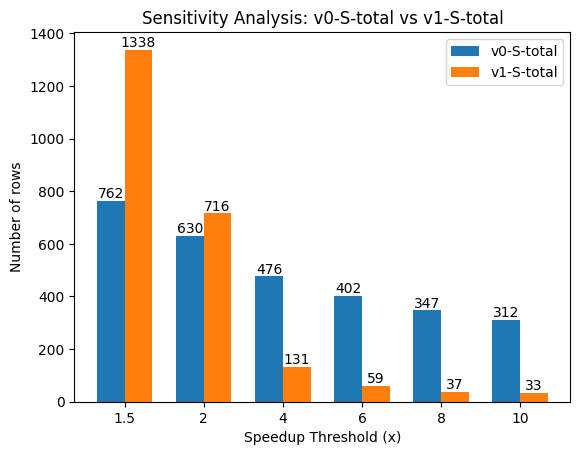

In [356]:
# =========================
# CONFIG
# =========================

col_a = "v0-S-total"
col_b = "v1-S-total"
va = col_a.split("-")[0]
vb = col_b.split("-")[0]
thresholds = [1.5, 2, 4, 6, 8, 10]
min_time_threshold = 1.0

# =========================
# Handle zeros
# =========================
df = df.replace(0, 0.01)

# =========================
# Filter
# =========================
df_filtered = df[
    (df[col_a] >= min_time_threshold) | (df[col_b] >= min_time_threshold)
].copy()

# =========================
# Compute speedups
# =========================
df_filtered["speedup_a"] = df_filtered[col_b] / df_filtered[col_a]
df_filtered["speedup_b"] = df_filtered[col_a] / df_filtered[col_b]

# =========================
# Threshold = 2 analysis
# =========================
threshold_check = thresholds[0]

a_wins = df_filtered[df_filtered["speedup_a"] >= threshold_check].copy()
b_wins = df_filtered[df_filtered["speedup_b"] >= threshold_check].copy()

# =========================
# Determine weaker & stronger
# =========================
if len(a_wins) < len(b_wins):
    weaker = "A"
    stronger = "B"
elif len(b_wins) < len(a_wins):
    weaker = "B"
    stronger = "A"
else:
    weaker = "Tie"
    stronger = "Tie"


# =========================
# Formatting function (SIDE-AWARE)
# =========================
max_len = 25

def format_df(df_in, side):
    if side == "A":
        speedup_series = df_in["speedup_a"].map(lambda x: f"{x:.2f}x")
        speedup_name = f"{col_b}/{col_a}"
    else:
        speedup_series = df_in["speedup_b"].map(lambda x: f"{x:.2f}x")
        speedup_name = f"{col_a}/{col_b}"

    return df_in.assign(
        dataset=df_in["dataset"].apply(
            lambda x: (str(x)[:max_len] + "...") if len(str(x)) > max_len else str(x)
        ),
        speedup=speedup_series
    )[[
        "dataset", "k",
        col_a, col_b,
        "speedup",
        f"{va}-ctcp", f"{vb}-ctcp",
        f"{va}-heur", f"{vb}-heur",
        f"{va}-init", f"{vb}-init",
        f"{va}-prep", f"{vb}-prep",
        f"{va}-S-total", f"{vb}-S-total",
        f"{va}-R-total", f"{vb}-R-total",
        f"{va}-P-total", f"{vb}-P-total"
    ]]
    # .rename(columns={"speedup": f"speedup ({speedup_name})"})

# =========================
# Print summary
# =========================
print(f"\n=== Threshold {threshold_check} Analysis ===")
print(f"{col_a} wins: {len(a_wins)}")
print(f"{col_b} wins: {len(b_wins)}")

# =========================
# Display results
# =========================
if weaker == "Tie":
    print("Both sides have equal wins.")

    print("\n--- Side A (>= threshold) ---")
    display_scroll(
        format_df(a_wins.sort_values(by=f"{col_a}", ascending=False), "A")
        # format_df(a_wins.sort_values(by="{speedup_a}", ascending=False), "A")
    )

    print("\n--- Side B (>= threshold) ---")
    display_scroll(
        format_df(b_wins.sort_values(by=f"{col_b}", ascending=False), "B")
        # format_df(a_wins.sort_values(by="{speedup_b}", ascending=False), "A")
    )

else:
    if weaker == "A":
        weaker_df = a_wins.sort_values(by=f"{col_a}", ascending=False)
        stronger_df = b_wins.sort_values(by=f"{col_b}", ascending=False)
        # weaker_df = a_wins.sort_values(by="speedup_a", ascending=False)
        # stronger_df = b_wins.sort_values(by="speedup_b", ascending=False)
        weaker_name, stronger_name = col_a, col_b

        print(f"\n--- Weaker side: {weaker_name} ---")
        display_scroll(format_df(weaker_df, "A"))

        print(f"\n--- Stronger side: {stronger_name} ---")
        display_scroll(format_df(stronger_df, "B"))

    else:
        weaker_df = b_wins.sort_values(by=f"{col_b}", ascending=False)
        stronger_df = a_wins.sort_values(by=f"{col_a}", ascending=False)
        # weaker_df = b_wins.sort_values(by="speedup_b", ascending=False)
        # stronger_df = a_wins.sort_values(by="speedup_a", ascending=False)
        weaker_name, stronger_name = col_b, col_a

        print(f"\n--- Weaker side: {weaker_name} ---")
        display_scroll(format_df(weaker_df, "B"))

        print(f"\n--- Stronger side: {stronger_name} ---")
        display_scroll(format_df(stronger_df, "A"))

# =========================
# Sensitivity analysis
# =========================
a_counts = []
b_counts = []

for t in thresholds:
    a_counts.append((df_filtered["speedup_a"] >= t).sum())
    b_counts.append((df_filtered["speedup_b"] >= t).sum())

# =========================
# Plot
# =========================
x = range(len(thresholds))
width = 0.35

plt.figure()

bars_a = plt.bar([i - width/2 for i in x], a_counts, width, label=col_a)
bars_b = plt.bar([i + width/2 for i in x], b_counts, width, label=col_b)

def add_labels(bars):
    for bar in bars:
        height = bar.get_height()
        plt.text(
            bar.get_x() + bar.get_width()/2,
            height,
            f"{int(height)}",
            ha='center',
            va='bottom'
        )

add_labels(bars_a)
add_labels(bars_b)

plt.xticks(x, thresholds)
plt.xlabel("Speedup Threshold (x)")
plt.ylabel("Number of rows")
plt.title(f"Sensitivity Analysis: {col_a} vs {col_b}")

plt.legend()
plt.show()